1. Nous chargeons et lisons notre database en précisant que la séparation des colonnes du csv est faite part un `point virugle (;)` et non une  `virgule (,)`

In [2]:
import pandas as pd

df = pd.read_csv("project_dataset.csv", sep=";")

## 2. Nous cherchons toutes les informations et les valeurs qui sont nulles 

In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype
---  ------                                                                                       --------------  -----
 0   Date                                                                                         12010 non-null  str  
 1   Service                                                                                      11830 non-null  str  
 2   Gare de départ                                                                               12011 non-null  str  
 3   Gare d'arrivée                                                                               12011 non-null  str  
 4   Durée moyenne du trajet                                                                      11830 non-null  str  
 5   Nombre de circulations prévues                           

Date                                                                                              60
Service                                                                                          240
Gare de départ                                                                                    59
Gare d'arrivée                                                                                    59
Durée moyenne du trajet                                                                          240
Nombre de circulations prévues                                                                   240
Nombre de trains annulés                                                                         239
Commentaire annulations                                                                        11493
Nombre de trains en retard au départ                                                             240
Retard moyen des trains en retard au départ                                                

## 3. Nous remarquons que _90%_ des commentaires sont nulles donc nous retirons les colonnes car elles ne servent à rien pour un modèle de prédiction

In [4]:
df.drop(
    columns=[
        "Commentaire annulations",
        "Commentaire retards au départ",
        "Commentaire retards à l'arrivée",
    ],
    inplace=True,
)

---
4. Nous supprimons les doublons

In [5]:
df.drop_duplicates()

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141.0,870,5.0,289.0,11.24780854,3.693179191,...,110.0,6.51,44.0,8.0,36.13445378,31.09243697,10.92436975,15.96638655,"5,04",0.840336134
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56.0,406.0,1.0,213.0,8.479968701,4.567119342,...,32.0,5.363539095,9.0,4.0,20.0,35.0,16.66666667,16.66666667,8.333333333,3.333333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166.0,226.0,0.0,21.0,6.23968254,0.286283186,...,11.0,2.938053097,6.0,1.0,22.22222222,27.77777778,16.66666667,16.66666667,5.555555556,11.11111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,216.21,508.0,3.0,71.0,7.235211268,0.98,...,39.0,5.292211221,18.0,NaN,33.33333333,22.22222222,16.66666667,20.37037037,5.555555556,1.851851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94.0,472.0,4.0,224.0,6.784672619,3.229700855,...,42.0,4.882371795,10.0,0.0,15.78947368,45.61403509,NaN,15.78947368,1.754385965,1.754385965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12033,11-2018,National,SAINT ETIENNE CHATEAUCREUX,PARIS LYON,168.0,113.0,1.0,19.0,5.662280702,0.854761905,...,14.0,5.510416667,5.0,2.0,21.05263158,36.84210526,5.263157895,21.05263158,10.52631579,5.263157895
12034,2021/05,NaN,PARIS MONTPARNASSE,NANTES,138.0,470.0,29.0,48.0,4.22569444444444,0.151738473167045,...,6.0,31.4527777777778,3.0,0.0,22.2222222222222,0.0,11.1111111111111,33.3333333333333,0.0,33.3333333333333
12049,2018-03,NaN,PERPIGNAN,PARIS LYON,305.0,163.0,1.0,63.0,8.189417989,3.216769547,...,23.0,8.470884774,14.0,7.0,57.14285714,14.28571429,14.28571429,14.28571429,0.0,0.0
12056,2019 02,National,NICE VILLE,PARIS LYON,357.0,159.0,4.0,32.0,6.80625,1.463978495,...,33.0,9.321935484,13.0,5.0,18.18181818,36.36363636,24.24242424,12.12121212,9.090909091,0.0


---
5. Nous remarquons que _~2%_ des valeurs sont nulles : 240 pour 12000 entrées 
alors nous les remplaçons par leurs **médianes respectives**

In [6]:
for col in df.select_dtypes(include="number").columns:
    df[col].fillna(df[col].median())

---
6. Nous remplaçons le type de nos données par un type plus approprié : `Objet à Mixed`

In [7]:
df["Date"] = pd.to_datetime(df["Date"], format="mixed")

numeric_cols = [
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard au départ",
    "Retard moyen des trains en retard au départ",
    "Retard moyen de tous les trains au départ",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
    "Nombre trains en retard > 15min",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
]

for col in numeric_cols:
    df[col] = df[col].str.replace(
        ",", ".", regex=False
    )  # certaines valeurs sont avec des , et non des . donc on change
    df[col] = df[col].apply(
        lambda x: str(x).split()[0] if pd.notnull(x) else x
    )  # certaine valeurs sont "7.4 min" dcp on splut pour enlever le min
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )  # on convertit les valeurs object en numeriques

categorical_cols = ["Service", "Gare de départ", "Gare d'arrivée"]
for col in categorical_cols:
    df[col] = df[col].astype(
        "category"
    )  # on les convertit en category car pas vraiment utile

for col in numeric_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )  # on remplace les NaN que on a convertit avant en split par leur median

---
7. Nous remplaçons les valuers NaN dans les types category que nous avons cree juste avant par mode() qui est la valeur la plus présente de la colonne

In [8]:
cat_cols = df.select_dtypes(include="category").columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

## 8. On fait les features avec la date pour que ce soit plus pratique pour notre modele

In [9]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df.drop(columns=["Date"], inplace=True)  # on surppimes les dates plus utiles maintenant
df = df[
    df["Year"].notna() & df["Month"].notna()
]  # on ne garde que lkes lignes ou la date est presente

## 
9. Nous réecrivons nos données triées en créeant un _ficher csv_ :  `cleaned_dataset.csv`

In [10]:
df.to_csv("cleaned_dataset.csv", index=False)

## 10. On verifie que notre nouveau fichier ne contiennent aucunes valeurs vides et on verifie tous les types

In [11]:
df = pd.read_csv("cleaned_dataset.csv")
df.isnull().sum()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12010 entries, 0 to 12009
Data columns (total 24 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Service                                                                                      12010 non-null  str    
 1   Gare de départ                                                                               12010 non-null  str    
 2   Gare d'arrivée                                                                               12010 non-null  str    
 3   Durée moyenne du trajet                                                                      12010 non-null  float64
 4   Nombre de circulations prévues                                                               12010 non-null  float64
 5   Nombre de trains annulés                   

## 11. On genere un sommaire pour mieux comprendre les statistiques

In [12]:
df[
    numeric_cols
].describe()  ## on peut voir grace a ca le nombre de valeurs non nulles analysees et on peut voir aussi les moyennes pour chacun d'entre eux leur min et max etc..

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000,12010.000000
mean,170.787184,269.640966,8.541216,86.130142,12.257180,3.108087,37.143714,35.165796,6.037550,26.669192,36.183713,12.394671,5.101915,21.460254,21.849677,20.336823,18.850688,7.322678,7.526567
std,87.332872,180.583872,22.505343,89.976361,11.685783,5.082605,30.863766,15.557260,6.941407,22.337327,19.569481,11.940045,5.914829,15.744811,14.763053,14.527092,13.399538,7.939000,9.360935
min,0.000000,0.000000,0.000000,0.000000,0.000000,-229.269444,0.000000,-40.109259,-472.638889,0.000000,-2.714286,-44.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,100.692500,152.000000,0.000000,22.000000,6.240513,1.220219,15.000000,25.921461,3.431159,11.000000,28.042969,4.000000,1.000000,10.714286,12.152690,10.526316,10.151069,0.000000,0.000000
50%,163.000000,229.000000,2.000000,52.000000,10.355000,2.324187,29.000000,33.467867,5.352340,21.000000,37.502151,9.000000,3.000000,19.047619,20.000000,18.750000,17.073171,5.882353,5.000000
75%,222.000000,351.000000,7.000000,125.000000,15.601509,3.889494,50.000000,42.299219,8.015680,36.000000,46.700020,17.000000,7.000000,29.411765,29.411765,28.205128,25.000000,10.869565,11.111111
max,786.000000,1100.000000,297.000000,1066.000000,316.188000,115.047390,376.000000,299.600000,92.000000,312.000000,299.600000,202.000000,71.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


## 12. On regarde les Services , Gare de départ , Gare d'arrivée leur nombre d'utilisations

In [13]:
for col in ["Service", "Gare de départ", "Gare d'arrivée"]:
    print(df[col].value_counts())

Service
National         10556
International     1454
Name: count, dtype: int64
Gare de départ
PARIS LYON              2450
PARIS MONTPARNASSE      1528
PARIS EST                584
LYON PART DIEU           574
MARSEILLE ST CHARLES     523
                        ... 
 ZURICH                    1
Nantes                     1
 DOUAI                     1
ANGERS ST LAUD             1
nimes                      1
Name: count, Length: 132, dtype: int64
Gare d'arrivée
PARIS LYON              2457
PARIS MONTPARNASSE      1531
PARIS EST                578
LYON PART DIEU           578
MARSEILLE ST CHARLES     436
                        ... 
lyon part dieu             1
Stuttgart                  1
Francfort                  1
 NANCY                     1
 TOULOUSE MATABIAU         1
Name: count, Length: 116, dtype: int64


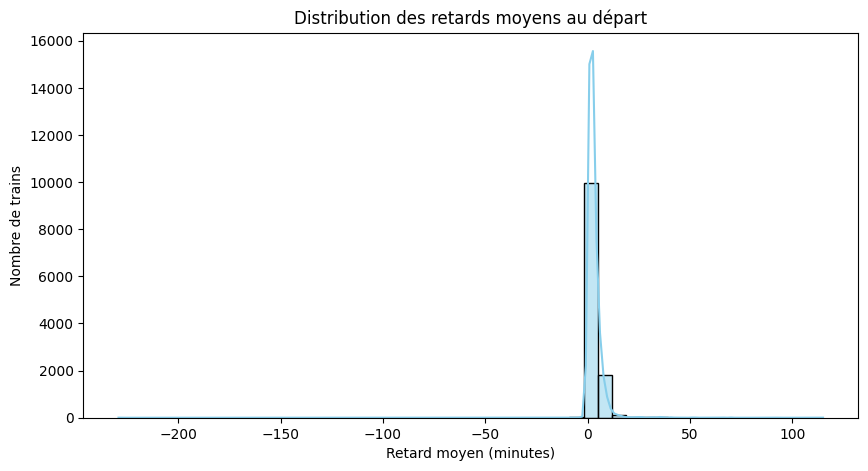

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 5))
sns.histplot(
    df["Retard moyen de tous les trains au départ"], bins=50, kde=True, color="skyblue"
)
plt.title("Distribution des retards moyens au départ")
plt.xlabel("Retard moyen (minutes)")
plt.ylabel("Nombre de trains")
plt.show()

/var/folders/pw/kmkjdpn13yg99_nmn2hj8z5h0000gn/T/ipykernel_53985/1028108390.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_gare_retard.index, y=top_gare_retard.values, palette="magma")


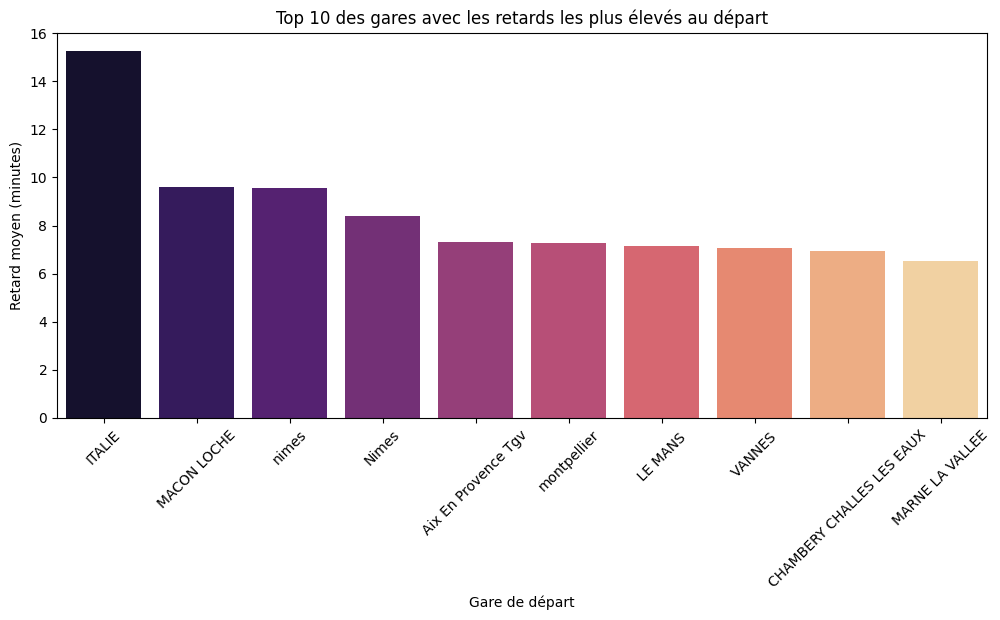

In [15]:
plt.figure(figsize=(12, 5))
top_gare_retard = (
    df.groupby("Gare de départ")["Retard moyen de tous les trains au départ"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=top_gare_retard.index, y=top_gare_retard.values, palette="magma")
plt.xticks(rotation=45)
plt.ylabel("Retard moyen (minutes)")
plt.title("Top 10 des gares avec les retards les plus élevés au départ")
plt.show()

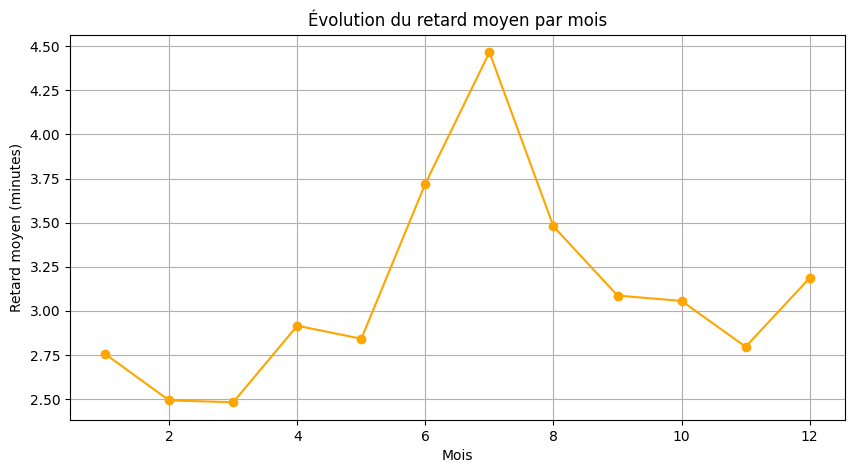

In [16]:
plt.figure(figsize=(10, 5))
df.groupby("Month")["Retard moyen de tous les trains au départ"].mean().plot(
    kind="line", marker="o", color="orange"
)
plt.xlabel("Mois")
plt.ylabel("Retard moyen (minutes)")
plt.title("Évolution du retard moyen par mois")
plt.grid(True)
plt.show()

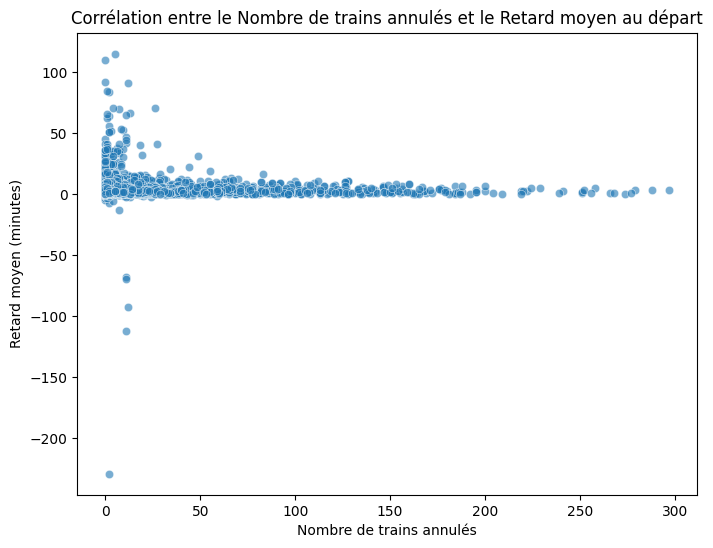

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.scatterplot(
    x="Nombre de trains annulés",
    y="Retard moyen de tous les trains au départ",
    data=df,
    alpha=0.6
)

plt.title("Corrélation entre le Nombre de trains annulés et le Retard moyen au départ")
plt.xlabel("Nombre de trains annulés")
plt.ylabel("Retard moyen (minutes)")
plt.show()